# 12장 · 구조화된 출력이란?

구조화된 출력은 프로그램이 정해진 필드에서 값을 꺼낼 수 있도록 만든 응답입니다. 행사명, 시작일, 대상을 각각 꺼낼 수 있어도 값이 원문과 맞는지는 별도로 확인해야 합니다.

실습 커널은 Python 3.12, pydantic 2.14.1, openai 3.35.1, httpx 0.28.1, langchain-classic 1.0.8, langchain-core 1.6.12를 사용합니다. 두 파서 패키지가 없다면 첫 실행 전에 노트북 셀에서 %pip install langchain-classic==1.0.8 langchain-core==1.6.12 를 실행하고 커널을 다시 시작하세요. 예제는 모의 응답으로 실행하므로 API 키가 필요 없습니다.

먼저 모든 셀을 실행하세요. 과제 셀의 `...`를 채운 뒤 그 셀을 다시 실행하고, 바로 아래 정답을 펼쳐 내 코드와 출력을 비교하세요.


## JSON의 null과 필수 키 누락

### 셀 01 · json.loads()의 null 변환

원문에는 시작일을 나중에 안내한다고 적혀 있습니다. 모델이 start에 null을 넣어 보냈습니다. 파이썬으로 이 값을 읽어 봅시다.

**null이 든 필드와 누락된 필드**　왼쪽 서식에는 null을 담은 칸이 있습니다. 오른쪽 서식의 빈 공간은 항목 자체가 빠진 경우입니다. 코드에서는 키의 존재 여부를 in으로 확인합니다.

[웹 교재에서 열기](https://langchain-lecture.vercel.app/chapter12/index.html#concept-clip)


In [1]:
import json

raw = '{"title":"독서 모임","start":null,"audience":"adult"}'
notice = json.loads(raw)
print(notice["start"])

None


None이 나왔습니다. start라는 칸은 있고 날짜만 비어 있다는 뜻입니다. start를 통째로 빼면 같은 줄에서 KeyError가 납니다. 꺼낼 칸이 없기 때문입니다.


### 과제 01 · in으로 필수 키 검사

has_start의 빈칸에 식 하나를 넣으세요. start가 있으면 값이 None이어도 True, 키가 빠졌으면 False가 나와야 합니다.


In [2]:
def has_start(record):
    return ...  # 키가 있는지 검사

missing = {"title": "독서 모임", "audience": "adult"}
print(has_start(missing))

Ellipsis


<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>def has_start(record):
    return &quot;start&quot; in record

missing = {&quot;title&quot;: &quot;독서 모임&quot;, &quot;audience&quot;: &quot;adult&quot;}
print(has_start(missing))</code></pre>
<p>실행 결과</p><pre>False</pre><p>이 공지에는 start가 없으므로 False입니다. 날짜가 미정인 공지라면 값이 None이어도 start라는 키는 있으므로 True가 됩니다.</p>
</details>


## Pydantic BaseModel과 Literal로 필드 정의

### 셀 02 · BaseModel로 Notice 정의

이제 행사명, 시작일, 대상을 어떻게 적을지 코드로 정합니다. Notice는 공지 한 건의 규칙을 담은 Pydantic 모델입니다. 셀을 실행하면 꼭 있어야 하는 항목의 이름이 나옵니다.


In [3]:
from typing import Literal
from pydantic import BaseModel, ConfigDict, ValidationError

class Notice(BaseModel):
    model_config = ConfigDict(extra="forbid", strict=True)
    title: str
    start: str | None
    audience: Literal["adult", "child", "unknown"]

print(Notice.model_json_schema()["required"])

['title', 'start', 'audience']


출력 목록에 start도 들어 있습니다. str | None은 날짜를 문자열로 적거나 미정일 때 None을 쓰도록 허용합니다. 기본값을 지정하지 않았으므로 start 자체를 빼면 오류가 납니다. audience에는 Literal에 적은 세 값만 쓸 수 있고, extra="forbid" 때문에 세 항목 외에 다른 항목을 덧붙여도 오류가 납니다.


### 셀 03 · model_validate()와 원문 대조

원문은 독서 모임 공지인데, 모델이 행사명을 ‘요리 모임’으로 잘못 읽었다고 해 봅시다. 이 응답을 Notice에 넣으면 어떻게 될까요?


In [4]:
reply_notice = {"title": "요리 모임", "start": None, "audience": "adult"}
checked = Notice.model_validate(reply_notice)
print(checked.title)

요리 모임


오류 없이 ‘요리 모임’이 나옵니다. 두 번째 줄에서 Notice가 확인한 것은 title에 문자열이 들어 있는지입니다. 공지 원문은 이 함수에 건네지도 않았으니, 행사명이 바뀌었는지는 알아낼 수 없습니다.


### 과제 02 · ValidationError.errors()의 loc

이번 공지에는 audience에 everyone이 들어 있습니다. 빈칸을 채워 Pydantic이 오류를 발견한 필드 이름을 출력하세요. 첫 오류의 loc에는 문제가 생긴 위치가 순서대로 들어 있습니다.


In [5]:
reply_notice = {"title": "독서 모임", "start": None, "audience": "everyone"}
try:
    Notice.model_validate(reply_notice)
except ValidationError as error:
    first_error = error.errors()[0]
    field = ...
    print(field)

Ellipsis


<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>reply_notice = {&quot;title&quot;: &quot;독서 모임&quot;, &quot;start&quot;: None, &quot;audience&quot;: &quot;everyone&quot;}
try:
    Notice.model_validate(reply_notice)
except ValidationError as error:
    first_error = error.errors()[0]
    field = first_error[&quot;loc&quot;][0]
    print(field)</code></pre>
<p>실행 결과</p><pre>audience</pre><p>Literal에 적은 선택지에 everyone이 없어 ValidationError가 납니다. 이때 첫 오류의 loc는 (&#x27;audience&#x27;,)이므로 첫 값을 꺼내면 오류가 난 필드 이름을 얻습니다.</p>
</details>


## LangChain 출력 파서 비교

모델에 보낼 형식을 지정하는 방식 외에, 이미 받은 문자열을 프로그램에서 해석하는 방법도 있습니다. 같은 공지에서 행사명과 대상 두 필드만 골라 두 파서를 비교합니다. 저장된 입력으로 실행하므로 API 키는 필요하지 않습니다.

비교 예제의 실행 환경은 langchain-classic 1.0.8, langchain-core 1.6.12, Pydantic 2.14.1입니다. 파서 패키지가 없는 커널에서는 먼저 노트북 셀에서 %pip install langchain-classic==1.0.8 langchain-core==1.6.12 를 실행하고 커널을 다시 시작하세요.

### 같은 everyone을 두 파서가 다르게 처리하는 이유

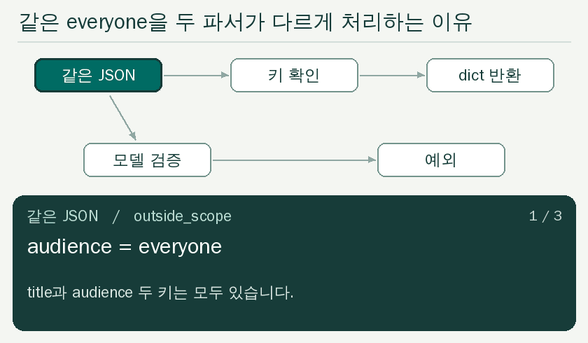

StructuredOutputParser에서 통과한 입력을 PydanticOutputParser에 그대로 넣습니다. 이번에는 EventSummary의 Literal 규칙까지 적용됩니다.


### StructuredOutputParser로 필수 키 읽기

모델이 보낸 JSON 문자열에서 행사명과 대상을 꺼내 봅니다. ResponseSchema는 필드 이름과 설명을 담습니다. get_format_instructions()는 모델에 보여 줄 형식 안내를 만들고, parse()는 이미 받은 문자열을 딕셔너리로 바꿉니다.

In [6]:
from langchain_classic.output_parsers.structured import ResponseSchema, StructuredOutputParser

fields = [
    ResponseSchema(name="title", description="행사 이름"),
    ResponseSchema(name="audience", description="참가 대상"),
]
field_parser = StructuredOutputParser.from_response_schemas(fields)
raw_notice = '{"title":"독서 모임","audience":"adult"}'
parsed_fields = field_parser.parse(raw_notice)
print(type(parsed_fields).__name__, parsed_fields["title"])

dict 독서 모임


dict와 행사명이 출력됩니다. 파서가 읽은 title은 딕셔너리의 키로 꺼냅니다.

### StructuredOutputParser가 확인하는 범위

필드 설명에 참가 대상을 적어 놓으면 허용하지 않은 값까지 걸러질까요? audience 키를 남겨 두고 값만 바꿔 보세요.

In [7]:
outside_scope = '{"title":"독서 모임","audience":"everyone"}'
print(field_parser.parse(outside_scope)["audience"])

everyone


everyone이 그대로 나옵니다. 이 파서는 예상한 키가 있는지 확인했지만 adult만 허용한다는 값 제약은 검사하지 않았습니다.

### PydanticOutputParser로 필드 값 검증

허용 대상을 adult로 한정한 모델을 정의하고 같은 JSON을 읽습니다. parse()가 돌려준 모델에서는 점을 찍어 속성을 읽습니다.

In [8]:
from typing import Literal
from pydantic import BaseModel
from langchain_core.output_parsers import PydanticOutputParser

class EventSummary(BaseModel):
    title: str
    audience: Literal["adult"]

typed_parser = PydanticOutputParser(pydantic_object=EventSummary)
parsed_event = typed_parser.parse(raw_notice)
print(type(parsed_event).__name__, parsed_event.audience)

EventSummary adult


EventSummary 인스턴스가 만들어졌습니다. audience는 모델이 허용한 adult입니다.

### OutputParserException으로 허용값 위반 확인

앞에서 everyone이 통과했던 문자열을 같은 값 그대로 다시 보냅니다.

In [9]:
from langchain_core.exceptions import OutputParserException

try:
    typed_parser.parse(outside_scope)
except OutputParserException as error:
    print(type(error).__name__)

OutputParserException


이번에는 파싱 예외가 발생합니다. Literal에 없는 값이기 때문입니다. 두 파서 모두 원문을 전달받지 않았으므로 행사명이 사실과 맞는지까지 판단하지는 않습니다.

## OpenAI의 text.format과 JSON Schema

### 셀 04 · model_json_schema()와 text.format

셀 02에서 정한 Notice의 규칙을 요청에도 넣어 봅시다. Notice.model_json_schema()로 규칙을 꺼내 쓰면 나중에 선택지를 바꿀 때 Notice 한 곳만 고치면 됩니다.


In [10]:
format_spec = {"type": "json_schema", "name": "notice",
               "strict": True, "schema": Notice.model_json_schema()}
request_options = {"input": "성인 독서 모임을 엽니다. 시작일은 추후 안내합니다.",
                   "instructions": "원문에 없는 시작일은 null로 기록하세요.",
                   "text": {"format": format_spec}}
print(format_spec["schema"]["properties"]["audience"]["enum"])

['adult', 'child', 'unknown']


이 셀은 요청에 넣을 request_options를 만듭니다. 실제로 SDK를 호출하는 코드는 셀 09에 있습니다. 요청에서 형식을 지정해도 모델이 응답을 거절하거나 응답이 도중에 끊길 수 있으니, 받은 내용은 따로 검사합니다.


## Responses API의 output과 content

### 셀 05 · output에서 message와 content 추출

셀 05의 response는 실제 응답에서 필요한 항목만 남겨 만든 예입니다. output 안에 항목이 둘 있습니다. 공지 본문이 어느 쪽에 들어 있는지 먼저 찾아보세요.

응답의 output 목록에서 바깥 item을 먼저 찾으세요. reasoning을 건너뛰고 message의 content로 들어가 output_text의 text를 읽습니다.


In [11]:
message = {"type": "message", "content": [{"type": "output_text", "text": raw}]}
response = {"status": "completed",
            "output": [{"type": "reasoning"}, message]}
def message_parts(response):
    parts = []
    for item in response["output"]:
        if item["type"] == "message":
            parts.extend(item["content"])
    return parts

print(message_parts(response)[0]["text"])

{"title":"독서 모임","start":null,"audience":"adult"}


output의 첫 항목은 reasoning이고, 공지가 들어 있는 message는 그 뒤에 있습니다. message_parts는 message를 찾아 content를 꺼냅니다. 화면에 찍힌 본문은 아직 JSON 문자열이므로 공지로 쓰기 전에 Notice로 검사합니다.


### 과제 03 · output_text 조각 결합

join_text를 완성해 ‘독서 모임’을 출력하세요. type이 output_text인 조각에서만 text를 꺼내고, 받은 순서대로 이어 붙이세요. 거절을 처리하는 코드는 셀 06에서 다룹니다.


In [12]:
def join_text(parts):
    ...  # 이곳에 함수 본문 작성

parts_to_read = [{"type": "annotation"},
                 {"type": "output_text", "text": "독서 "},
                 {"type": "output_text", "text": "모임"}]
print(join_text(parts_to_read))

None


<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>def join_text(parts):
    texts = []
    for part in parts:
        if part[&quot;type&quot;] == &quot;output_text&quot;:
            texts.append(part[&quot;text&quot;])
    return &quot;&quot;.join(texts)

parts_to_read = [{&quot;type&quot;: &quot;annotation&quot;},
                 {&quot;type&quot;: &quot;output_text&quot;, &quot;text&quot;: &quot;독서 &quot;},
                 {&quot;type&quot;: &quot;output_text&quot;, &quot;text&quot;: &quot;모임&quot;}]
print(join_text(parts_to_read))</code></pre>
<p>실행 결과</p><pre>독서 모임</pre><p>첫 조각은 annotation이라 text가 없습니다. type을 확인한 뒤 글자만 모으면 이 조각을 건너뜁니다. ‘독서 ’ 끝의 공백도 본문의 일부라서, 그대로 붙여야 ‘독서 모임’이 됩니다.</p>
</details>


## 응답 상태와 model_validate()를 이용한 검증

### 셀 06 · 응답 상태와 스키마 검사

inspect_response는 먼저 status를 읽습니다. 응답이 끝까지 왔으면 메시지에 refusal이 있는지 살핍니다. 거절이 없을 때만 본문 조각을 이어 붙이고, 공백을 빼고도 글자가 남아 있으면 Notice로 형식을 검사합니다.


In [13]:
def inspect_response(response):
    if response["status"] != "completed":
        return {"ok": False, "reason": "incomplete"}
    parts = message_parts(response)
    if any(part["type"] == "refusal" for part in parts):
        return {"ok": False, "reason": "refusal"}
    text = "".join(p["text"] for p in parts if p["type"] == "output_text")
    if not text.strip():
        return {"ok": False, "reason": "empty"}
    try:
        data = Notice.model_validate_json(text)
    except ValidationError:
        return {"ok": False, "reason": "invalid_schema"}
    return {"ok": True, "data": data.model_dump()}

이 함수는 status가 completed가 아닌 경우를 모두 incomplete로 표시합니다. 한 메시지에 글과 거절이 함께 있어도 결과는 refusal입니다. 글을 모으기 전에 거절부터 확인하기 때문입니다. 함수를 호출한 쪽에서는 ok를 먼저 읽으세요. True이면 data에 공지가 있고, False이면 reason에 멈춘 이유가 들어 있습니다.


### 셀 07 · 빈 content 처리

서버는 응답을 마쳤다고 했는데 메시지를 열어 보니 content가 비어 있습니다. 이 응답 하나를 셀 06의 함수에 건네 봅시다.


In [14]:
empty_reply = {
    "status": "completed",
    "output": [{"type": "message", "content": []}],
}
print(inspect_response(empty_reply))

{'ok': False, 'reason': 'empty'}


status는 completed이지만 읽을 글이 한 글자도 없어 reason이 empty입니다. 이 경우에는 data가 없습니다. 13장에서 다음 함수에 공지를 건넬 때는 ok가 True인 경우에만 data를 꺼냅니다.


### 과제 04 · 검증 성공 데이터만 반환

원문을 확인할 사람에게 공지 한 건을 건네려 합니다. notice_for_review를 완성하세요. 검사가 성공했으면 data에 담긴 공지를, 실패했으면 None을 돌려주세요. 셀 05의 정상 응답으로 실행해 보세요.


In [15]:
def notice_for_review(result):
    ...  # 검사에 성공한 공지만 꺼내세요

print(notice_for_review(inspect_response(response)))

None


<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>def notice_for_review(result):
    if result[&quot;ok&quot;]:
        return result[&quot;data&quot;]
    return None

print(notice_for_review(inspect_response(response)))</code></pre>
<p>실행 결과</p><pre>{&#x27;title&#x27;: &#x27;독서 모임&#x27;, &#x27;start&#x27;: None, &#x27;audience&#x27;: &#x27;adult&#x27;}</pre><p>이번 응답에는 세 항목을 담은 data가 있어 공지를 꺼낼 수 있습니다. 셀 07처럼 본문이 비었으면 ok가 False이고 data가 없으므로 None을 돌려줍니다.</p>
</details>


## 스트리밍의 delta와 response.completed

### 셀 08 · output_text.delta 누적

서버의 완료 신호를 받기 전에 연결이 끊겼습니다. 아래 목록은 끊기기 전까지 도착한 이벤트입니다. delta에는 방금 도착한 글자가 들어 있습니다.


In [16]:
events = [
    {"type": "response.output_text.delta", "delta": "안녕"},
    {"type": "response.output_text.delta", "delta": "하세요."},
]

text = ""
for event in events:
    if event["type"] == "response.output_text.delta":
        text += event["delta"]
print(text)

안녕하세요.


화면에는 마침표까지 찍혔지만 events에는 response.completed가 없습니다. 받은 글자는 보여 줄 수 있어도 응답이 끝났다고 판단할 근거는 없습니다. 완료 이벤트가 오면 SDK의 event.response.usage에서 사용량을 읽을 수 있습니다. 완료 신호가 와도 사용량 값이 비어 있을 수 있으므로, 사용량만 보고 완료 여부를 판단하면 안 됩니다.


### 과제 05 · response.completed 판별

이번 연결에서는 마지막에 response.completed가 도착했지만 사용량 정보가 없습니다. 빈칸에 이벤트 이름을 써서, 완료 신호가 들어왔을 때만 True를 돌려주도록 완성하세요.


In [17]:
def is_complete(events):
    for event in events:
        if event["type"] == ...:
            return True
    return False

last_events = [{"type": "response.completed", "response": {}}]
print(is_complete(last_events))

False


<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>def is_complete(events):
    for event in events:
        if event[&quot;type&quot;] == &quot;response.completed&quot;:
            return True
    return False

last_events = [{&quot;type&quot;: &quot;response.completed&quot;, &quot;response&quot;: {}}]
print(is_complete(last_events))</code></pre>
<p>실행 결과</p><pre>True</pre><p>토큰 수가 없어도 type에 response.completed가 적혀 있으므로 True입니다. 셀 08처럼 글자 조각만 도착했다면 반복이 끝날 때까지 완료 신호를 찾지 못해 False가 됩니다.</p>
</details>


## responses.create()와 APITimeoutError

### 셀 09 · responses.create()와 model_dump()

이번에는 셀 06의 검사기를 SDK 호출에 연결합니다. 정상적으로 응답을 받으면 reply.model_dump()로 딕셔너리를 만들어 inspect_response에 건넵니다.


In [18]:
from openai import OpenAI, APITimeoutError

def request_notice(client):
    try:
        reply = client.responses.create(model="classroom-mock", **request_options)
    except APITimeoutError:
        return {"ok": False, "reason": "timeout"}
    return inspect_response(reply.model_dump())

기다리던 중 APITimeoutError가 발생하면 검사할 reply가 없습니다. 이때 request_notice는 reason에 timeout을 담아 돌려줍니다.


### 셀 10 · MockTransport로 시간 초과 재현

응답을 기다리다가 제한 시간이 지나면 어떻게 될까요? 아래 셀의 모의 연결은 요청을 보내는 순간 읽기 시간 초과를 일으킵니다. 연결 설정은 제공된 코드 그대로 두고 request_notice의 결과를 확인하세요.


In [19]:
import httpx

def timeout_transport(request):
    raise httpx.ReadTimeout("classroom timeout", request=request)

with OpenAI(
    api_key="classroom-placeholder",
    max_retries=0,
    http_client=httpx.Client(transport=httpx.MockTransport(timeout_transport)),
) as client:
    print(request_notice(client))

{'ok': False, 'reason': 'timeout'}


SDK가 APITimeoutError를 일으키면 셀 09의 함수가 reason에 timeout을 담습니다. 셀 07의 empty는 응답을 열어 보고 알게 된 결과였지요. 여기서는 검사할 응답을 받기 전에 기다리는 시간이 끝났습니다.


## 종합 실습 · 누락값을 보존하는 출력 규칙

### 과제 06 · 미확정 종료 시각과 기본값 처리

가상의 은행 앱에 “01:00부터 이체 점검. 종료 시각은 추후 안내합니다.”라는 공지가 올라왔습니다. 모델이 종료 시각으로 02:00을 뽑았다면 앱에 그대로 표시해도 될까요? 이번에는 형식 검사를 마친 값과 공지 원문에서 확인한 값을 비교합니다.

display_end를 완성하세요. confirmed_end는 원문에서 확인한 종료 시각이고 candidate_end는 모델이 뽑은 시각입니다. 두 값이 다르면 “원문 확인”, 둘 다 None이면 “종료 미정”을 돌려주세요. 두 값이 같은 시각이면 그 시각을 그대로 돌려주세요.


In [20]:
def display_end(confirmed_end, candidate_end):
    ...  # 세 경우의 판단과 결과 작성

print(display_end(None, "02:00"))

None


<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>def display_end(confirmed_end, candidate_end):
    if confirmed_end != candidate_end:
        return &quot;원문 확인&quot;
    if confirmed_end is None:
        return &quot;종료 미정&quot;
    return confirmed_end

print(display_end(None, &quot;02:00&quot;))</code></pre>
<p>실행 결과</p><pre>원문 확인</pre><p>원문은 종료 시각을 추후 안내한다고 했는데 모델은 02:00을 넣었습니다. 앱에 이 시각을 표시하려면 먼저 원문에서 확인해야 합니다. 둘 다 미정일 때는 ‘종료 미정’을, 나중에 공지된 시각과 추출한 시각이 같으면 그 시각을 표시합니다.</p>
</details>
